In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Mismos datos del CSV utilizado en el Tema 9
base = pd.DataFrame({
    "estacion": [
        "Centro",
        "San Jerónimo",
        "Wanchaq",
        "San Sebastián",
        "Poroy"
    ],
    "pm10_ugm3": [45, 28, 62, 35, np.nan],
    "no2_ppb": [18.2, 12.5, 25.4, 15.0, 9.8],
    "ruido_db": [72, 58, 81, 65, 52],
    "tipo_zona": [
        "Urbana", "Valle", "Urbana", "Urbana", "Altoandina"
    ]
})

base = base.set_index("estacion")

variables = ["pm10_ugm3", "no2_ppb", "ruido_db"]

# Carpeta donde se guardarán las imágenes
carpeta = Path.home() / "Downloads" / "tema10"
carpeta.mkdir(parents=True, exist_ok=True)

print("DATOS ORIGINALES")
display(base)

print("\nVALORES FALTANTES")
print(base[variables].isna().sum())

print("\nCarpeta de resultados:", carpeta)

DATOS ORIGINALES


,pm10_ugm3,no2_ppb,ruido_db,tipo_zona
estacion,,,,
Centro,45.0,18.2,72,Urbana
San Jerónimo,28.0,12.5,58,Valle
Wanchaq,62.0,25.4,81,Urbana
San Sebastián,35.0,15.0,65,Urbana
Poroy,NaN,9.8,52,Altoandina



VALORES FALTANTES
pm10_ugm3    1
no2_ppb      0
ruido_db     0
dtype: int64

Carpeta de resultados: C:\Users\51950\Downloads\tema10


In [2]:
# Seleccionar solamente las variables numéricas
datos = base[variables].copy()

# Aplicar el mismo tratamiento del Tema 9
medianas = datos.median()
datos = datos.fillna(medianas)

print("MEDIANAS")
print(medianas)

print("\nDATOS COMPLETOS")
display(datos)

# Matriz de correlación de Pearson
corr = datos.corr(method="pearson")

print("\nMATRIZ DE CORRELACIÓN")
display(corr.round(4))

assert not datos.isna().any().any()
assert datos.loc["Poroy", "pm10_ugm3"] == 40

print("\nVerificación correcta: PM10 de Poroy = 40.")

MEDIANAS
pm10_ugm3    40.0
no2_ppb      15.0
ruido_db     65.0
dtype: float64

DATOS COMPLETOS


,pm10_ugm3,no2_ppb,ruido_db
estacion,,,
Centro,45.0,18.2,72
San Jerónimo,28.0,12.5,58
Wanchaq,62.0,25.4,81
San Sebastián,35.0,15.0,65
Poroy,40.0,9.8,52



MATRIZ DE CORRELACIÓN


,pm10_ugm3,no2_ppb,ruido_db
pm10_ugm3,1.0000,0.8522,0.7940
no2_ppb,0.8522,1.0000,0.9844
ruido_db,0.7940,0.9844,1.0000



Verificación correcta: PM10 de Poroy = 40.


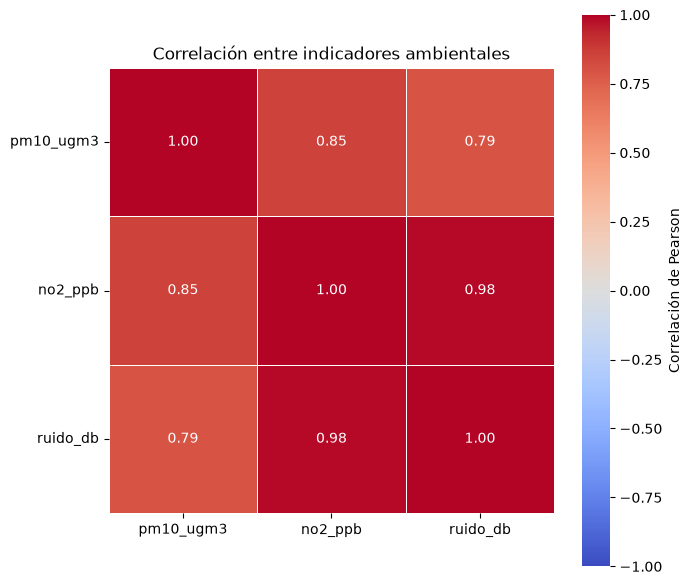

Imagen guardada: C:\Users\51950\Downloads\tema10\heatmap_seaborn.png


In [3]:
fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"},
    ax=ax
)

ax.set_title("Correlación entre indicadores ambientales")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()

archivo = carpeta / "heatmap_seaborn.png"
fig.savefig(archivo, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Imagen guardada:", archivo)

Celdas visibles: 3 de 9


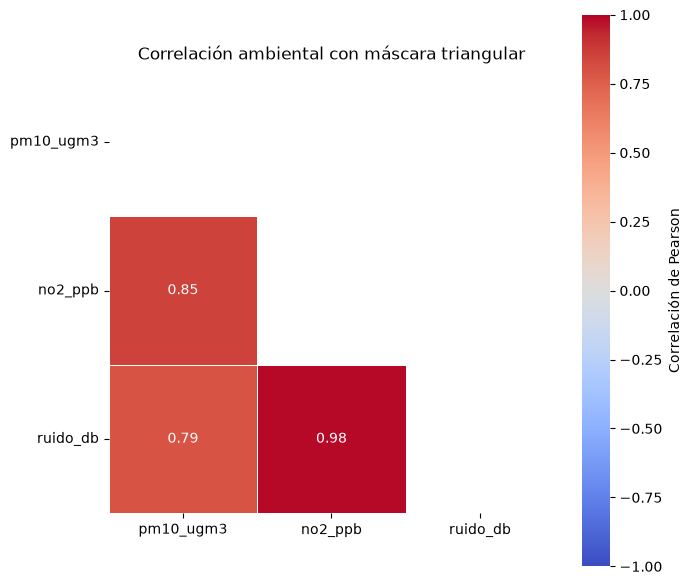

Imagen guardada: C:\Users\51950\Downloads\tema10\heatmap_seaborn_mascara.png


In [4]:
# True indica las celdas que se ocultarán.
# Se ocultan el triángulo superior y la diagonal.
mascara = np.triu(np.ones_like(corr, dtype=bool))

print("Celdas visibles:", (~mascara).sum(), "de", mascara.size)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    corr,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"},
    ax=ax
)

ax.set_title("Correlación ambiental con máscara triangular")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()

archivo = carpeta / "heatmap_seaborn_mascara.png"
fig.savefig(archivo, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Imagen guardada:", archivo)

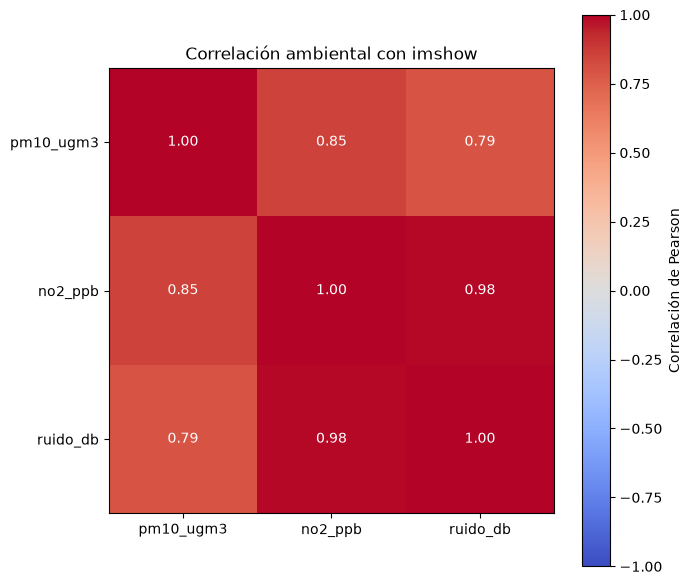

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))

imagen = ax.imshow(
    corr.to_numpy(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(variables)))
ax.set_yticks(range(len(variables)))
ax.set_xticklabels(variables)
ax.set_yticklabels(variables)

# Agregar cada coeficiente manualmente
for fila in range(len(variables)):
    for columna in range(len(variables)):
        valor = corr.iloc[fila, columna]
        ax.text(
            columna,
            fila,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color="white" if abs(valor) > 0.7 else "black"
        )

barra = fig.colorbar(imagen, ax=ax)
barra.set_label("Correlación de Pearson")

ax.set_title("Correlación ambiental con imshow")
fig.tight_layout()

plt.show()
plt.close(fig)